# Artificial Neural Networks — Lab Assignment 2
**COMSATS University Islamabad — Department of Computer Science**

- **Name:** Maryam Yaqoob
- **Registration No.:** FA23-BAI-025
- **Class:** BS AI-7
- **Subject:** ANN & DL
- **Submitted to:** Sir Zaeem Akbar
- **Submission deadline:** 19-10-2026

This notebook contains the code, input data, output and discussion for all four tasks of Lab Assignment 2.

## Assignment requirements (summary)
- **Task 1:** Train an MLP on Iris; compare weight initialisation, learning-rate strategies, batch sizes and epoch limits (5 epochs preferred), regularisation (L1/L2, dropout) with early stopping (restore best weights); show learning curves and justify under-/over-fit/good fit.
- **Task 2:** Adaline (LMS rule, sign threshold) on bipolar AND with weights, bias, predictions and MSE plot; Madaline (≥2 Adaline hidden units, bipolar output) on bipolar XOR; explain why a single Adaline cannot solve XOR.
- **Task 3:** Heteroassociative memory (≥3 pairs) and autoassociative memory (≥3 patterns), tested on clean and noisy inputs; table of stored pattern, noise, recalled output, exact match; discuss a failure case.
- **Task 4:** Hopfield network: Hebbian storage (≥3 patterns, zero diagonal), asynchronous recall with a stated tie rule, recall rate for corrupted inputs, and energy tracking with explanation.
- **Submission:** codes of all tasks in an MS-Word document along with input; name, registration number and class on the title page.

# Task 1 — ANN Training and Hyperparameter Investigation
**Input:** the Iris dataset (150 samples, 4 numeric features, 3 classes), loaded from `sklearn.datasets.load_iris`. It is split 60/20/20 into training/validation/test sets (stratified); `StandardScaler` is fitted on the training split only.

**Assumptions:** base MLP 4→16→16→3 (softmax) with the Adam optimiser; every comparison is the mean of 3 random initialisations (mean ± std); a larger 64-64 network and up to 300 epochs are used for the over-fitting study because Iris is too easy for a small network to over-fit.

In [1]:
"""
Lab Assignment 2 - Task 1: ANN Training and Hyperparameter Investigation
Dataset : Iris (sklearn, 150 samples, 4 features, 3 classes)
Model   : Multilayer Perceptron (Keras)

Assumptions (flagged explicitly):
  A1. Split is 60/20/20 (train/val/test), stratified, fixed seed.
  A2. StandardScaler is fitted on the TRAINING split only.
  A3. Iris is tiny and results are noisy, so every comparison is averaged
      over N_SEEDS random initialisations (mean +/- std reported).
  A4. Base architecture: 4 -> 16 -> 16 -> 3 (softmax); Adam optimiser.
  A5. "5 epochs" is used as the short epoch limit; 50 as the long limit.
  A6. For the overfitting study a larger net (64-64) and up to 300 epochs
      are used, because Iris is too easy for a small net to overfit.
"""
import os
import time
import random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

OUT = "task1_outputs"
os.makedirs(OUT, exist_ok=True)
SEED = 42
N_SEEDS = 3


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    tf.random.set_seed(s)

I0000 00:00:1791922415.885749     133 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791922441.883931     133 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# ----------------------------------------------------------------------
# 1. Data preparation
# ----------------------------------------------------------------------
iris = load_iris()
X, y = iris.data, iris.target

# 60% train, 40% temp -> temp split equally into 20% val and 20% test
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

scaler = StandardScaler().fit(X_train)          # fit on training data ONLY
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("=== DATA SPLIT ===")
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print("Train mean (should be ~0):", np.round(X_train.mean(axis=0), 3))
print("Train std  (should be ~1):", np.round(X_train.std(axis=0), 3))

=== DATA SPLIT ===
Train: (90, 4), Val: (30, 4), Test: (30, 4)
Train mean (should be ~0): [-0. -0. -0.  0.]
Train std  (should be ~1): [1. 1. 1. 1.]


In [3]:
# ----------------------------------------------------------------------
# Helpers
# ----------------------------------------------------------------------
class LRLogger(callbacks.Callback):
    """Records the learning rate used at the start of every epoch."""
    def on_train_begin(self, logs=None):
        self.lrs = []

    def on_epoch_begin(self, epoch, logs=None):
        self.lrs.append(float(keras.backend.get_value(self.model.optimizer.learning_rate)))


def build_model(activation="relu", init="he_normal", hidden=(16, 16),
                l1=0.0, l2=0.0, dropout=0.0, lr=0.01):
    reg = None
    if l1 > 0 or l2 > 0:
        reg = regularizers.l1_l2(l1=l1, l2=l2)
    m = keras.Sequential([layers.Input(shape=(4,))])
    for units in hidden:
        m.add(layers.Dense(units, activation=activation,
                           kernel_initializer=init, kernel_regularizer=reg))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(3, activation="softmax", kernel_initializer="glorot_uniform"))
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


def run(seed, epochs, batch_size, extra_callbacks=None, **model_kwargs):
    """Train one model; return (history dict, seconds, model, lr list)."""
    set_seed(seed)
    model = build_model(**model_kwargs)
    lr_logger = LRLogger()
    cbs = [lr_logger] + (extra_callbacks() if extra_callbacks else [])
    t0 = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=epochs, batch_size=batch_size, verbose=0, callbacks=cbs)
    return h.history, time.time() - t0, model, lr_logger.lrs


def pad(arr, n):
    """Pad a list to length n with its last value (for early-stopped runs)."""
    arr = list(arr)
    return arr + [arr[-1]] * (n - len(arr))


def ms(v):
    return f"{np.mean(v):.4f} +/- {np.std(v):.4f}"

### 1.1 Weight initialisation
**Expected effect:** He initialisation (variance 2/fan_in) compensates for ReLU zeroing half of the activations, while Xavier/Glorot (variance 2/(fan_in+fan_out)) suits symmetric activations such as tanh. A suitable initialisation keeps activation/gradient variance roughly constant from layer to layer, which avoids vanishing or exploding signals and speeds up early training.


=== EXPERIMENT 2: WEIGHT INITIALISATION (20 epochs, batch 16, lr 0.01) ===


relu  + he_normal       | epoch-1 train loss 1.1356 | final val loss 0.1707 +/- 0.0390 | final val acc 0.9333 +/- 0.0000


relu  + glorot_uniform  | epoch-1 train loss 0.9972 | final val loss 0.1355 +/- 0.0361 | final val acc 0.9333 +/- 0.0000


tanh  + glorot_uniform  | epoch-1 train loss 0.8812 | final val loss 0.1079 +/- 0.0071 | final val acc 0.9333 +/- 0.0000


tanh  + he_normal       | epoch-1 train loss 0.7997 | final val loss 0.1184 +/- 0.0143 | final val acc 0.9444 +/- 0.0157


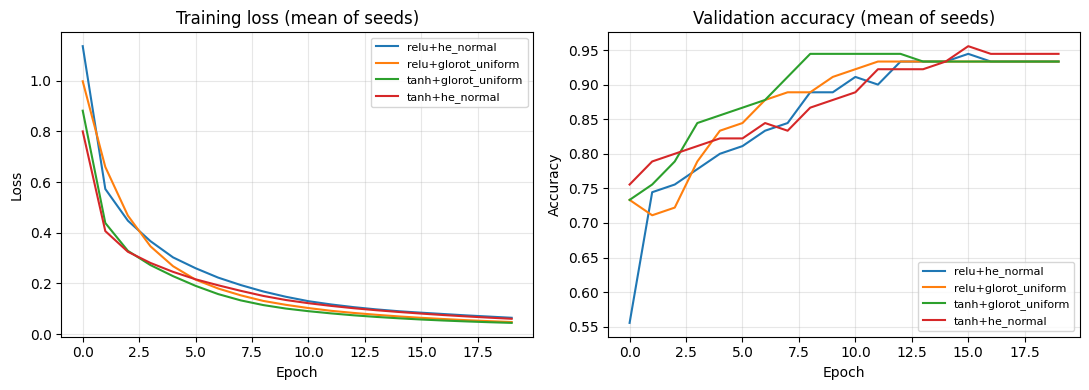

In [4]:
# ----------------------------------------------------------------------
# 2. Weight initialisation (ReLU: He vs Glorot ; tanh: Glorot vs He)
# ----------------------------------------------------------------------
print("\n=== EXPERIMENT 2: WEIGHT INITIALISATION (20 epochs, batch 16, lr 0.01) ===")
init_cfg = [("relu", "he_normal"), ("relu", "glorot_uniform"),
            ("tanh", "glorot_uniform"), ("tanh", "he_normal")]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for act, init in init_cfg:
    curves_l, curves_a, final_l, final_a = [], [], [], []
    for s in range(N_SEEDS):
        h, _, _, _ = run(SEED + s, 20, 16, activation=act, init=init)
        curves_l.append(h["loss"]); curves_a.append(h["val_accuracy"])
        final_l.append(h["val_loss"][-1]); final_a.append(h["val_accuracy"][-1])
    print(f"{act:5s} + {init:15s} | epoch-1 train loss {np.mean([c[0] for c in curves_l]):.4f} | "
          f"final val loss {ms(final_l)} | final val acc {ms(final_a)}")
    ax[0].plot(np.mean(curves_l, axis=0), label=f"{act}+{init}")
    ax[1].plot(np.mean(curves_a, axis=0), label=f"{act}+{init}")
ax[0].set(title="Training loss (mean of seeds)", xlabel="Epoch", ylabel="Loss")
ax[1].set(title="Validation accuracy (mean of seeds)", xlabel="Epoch", ylabel="Accuracy")
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_initialisation.png", dpi=150); plt.show()

**Observation:** All four combinations reach about 93–94 % validation accuracy after 20 epochs. tanh with Glorot gave the lowest validation loss and ReLU with He the highest, so the theoretical advantage of the matched initialisation is **not** visible here. This is expected: the network is shallow (two hidden layers) and the dataset tiny, so signal variance cannot vanish or explode, and with only 3 seeds the differences are within the run-to-run spread. The matched initialisations (He for ReLU, Glorot for tanh) are still the safe default for deeper networks.

### 1.2 Learning-rate strategies
A constant learning rate (0.05) is compared with exponential decay (0.05·0.92^epoch) and `ReduceLROnPlateau` (×0.5 after 3 epochs without validation-loss improvement). The learning rate used in every epoch is recorded and plotted.


=== EXPERIMENT 3: LEARNING-RATE STRATEGIES (60 epochs, batch 16, start lr 0.05) ===


Constant (0.05)                          | final val loss 0.1182 +/- 0.0475 | final val acc 0.9556 +/- 0.0157 | final lr 0.05000


Exponential decay (0.05*0.92^epoch)      | final val loss 0.1200 +/- 0.1127 | final val acc 0.9667 +/- 0.0272 | final lr 0.00040


ReduceLROnPlateau (x0.5, patience 3)     | final val loss 0.1159 +/- 0.1074 | final val acc 0.9556 +/- 0.0157 | final lr 0.00010


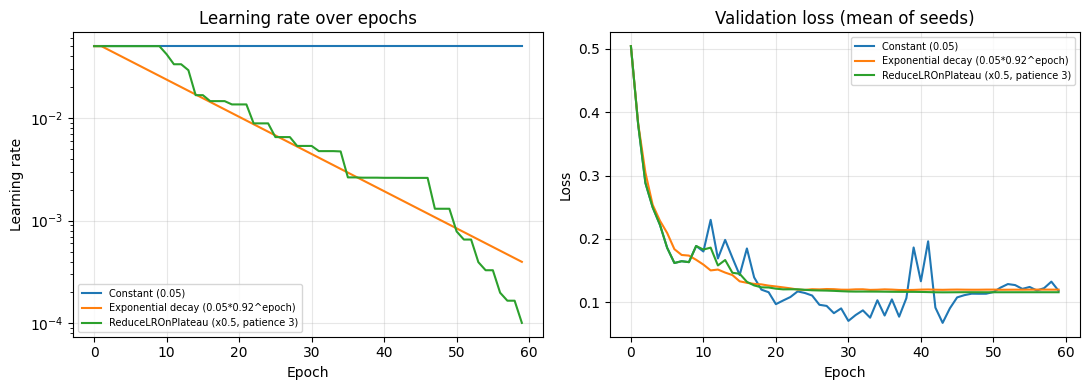

In [5]:
# ----------------------------------------------------------------------
# 3. Learning-rate strategies
# ----------------------------------------------------------------------
print("\n=== EXPERIMENT 3: LEARNING-RATE STRATEGIES (60 epochs, batch 16, start lr 0.05) ===")
EPOCHS_LR = 60


def cb_constant():
    return []


def cb_exp_decay():
    return [callbacks.LearningRateScheduler(lambda e, lr: 0.05 * (0.92 ** e))]


def cb_plateau():
    return [callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                        patience=3, min_lr=1e-5, verbose=0)]


lr_cfg = [("Constant (0.05)", cb_constant),
          ("Exponential decay (0.05*0.92^epoch)", cb_exp_decay),
          ("ReduceLROnPlateau (x0.5, patience 3)", cb_plateau)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, cb in lr_cfg:
    lrs_all, vl_all, va_all = [], [], []
    for s in range(N_SEEDS):
        h, _, _, lrs = run(SEED + s, EPOCHS_LR, 16, extra_callbacks=cb, lr=0.05)
        lrs_all.append(lrs); vl_all.append(h["val_loss"]); va_all.append(h["val_accuracy"])
    print(f"{name:40s} | final val loss {ms([v[-1] for v in vl_all])} | "
          f"final val acc {ms([v[-1] for v in va_all])} | final lr {np.mean([l[-1] for l in lrs_all]):.5f}")
    ax[0].plot(np.mean(lrs_all, axis=0), label=name)
    ax[1].plot(np.mean(vl_all, axis=0), label=name)
ax[0].set(title="Learning rate over epochs", xlabel="Epoch", ylabel="Learning rate", yscale="log")
ax[1].set(title="Validation loss (mean of seeds)", xlabel="Epoch", ylabel="Loss")
for a in ax:
    a.legend(fontsize=7); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_learning_rate.png", dpi=150); plt.show()

**Observation:** All three strategies end at 95.6–96.7 % validation accuracy, and the differences are inside the standard deviation. The constant rate stays at 0.05, so the validation loss keeps fluctuating. Exponential decay shrinks the rate smoothly (to about 4×10⁻⁴ at epoch 60), and `ReduceLROnPlateau` reduces it in steps only when validation loss stalls (to about 10⁻⁴). Decaying schedules make late-epoch updates smaller and therefore more stable, but on Iris the benefit is small.

### 1.3 Batch size and epoch limit
Batch sizes 8 and 32 are each trained for 5 epochs (the preferred limit) and 50 epochs; training time and validation behaviour are reported.


=== EXPERIMENT 4: BATCH SIZE x EPOCH LIMIT (lr 0.01) ===
batch epochs |   train time (s) |       final val loss |        final val acc


    8      5 | 2.4413 +/- 0.1859 |    0.3295 +/- 0.0335 |    0.8444 +/- 0.0157


    8     50 | 14.2613 +/- 0.1254 |    0.1523 +/- 0.0881 |    0.9556 +/- 0.0157


   32      5 | 2.1077 +/- 0.1043 |    0.5151 +/- 0.1246 |    0.7556 +/- 0.0416


   32     50 | 11.0217 +/- 1.3919 |    0.1375 +/- 0.0525 |    0.9444 +/- 0.0157


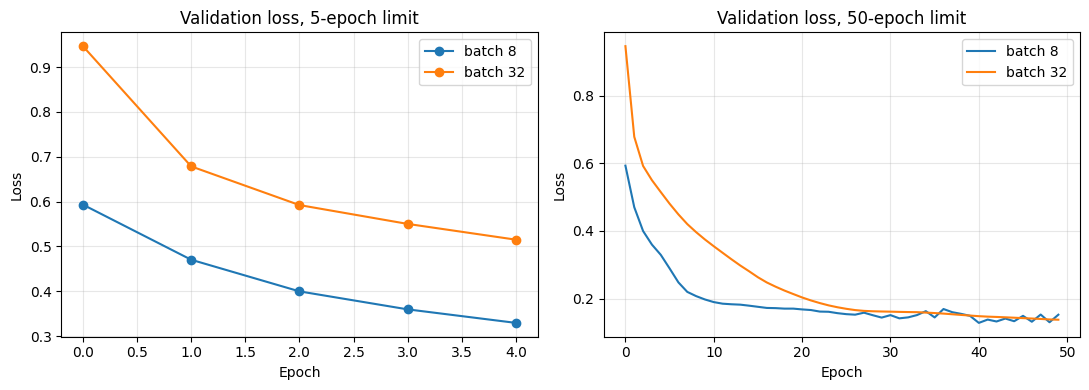

In [6]:
# ----------------------------------------------------------------------
# 4. Batch size x epoch limit
# ----------------------------------------------------------------------
print("\n=== EXPERIMENT 4: BATCH SIZE x EPOCH LIMIT (lr 0.01) ===")
print(f"{'batch':>5} {'epochs':>6} | {'train time (s)':>16} | {'final val loss':>20} | {'final val acc':>20}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for bs in (8, 32):
    for ep in (5, 50):
        times, vl, va, curves = [], [], [], []
        for s in range(N_SEEDS):
            h, t, _, _ = run(SEED + s, ep, bs)
            times.append(t); vl.append(h["val_loss"][-1]); va.append(h["val_accuracy"][-1])
            curves.append(h["val_loss"])
        print(f"{bs:>5} {ep:>6} | {ms(times):>16} | {ms(vl):>20} | {ms(va):>20}")
        if ep == 50:
            ax[1].plot(np.mean(curves, axis=0), label=f"batch {bs}")
        else:
            ax[0].plot(np.mean(curves, axis=0), marker="o", label=f"batch {bs}")
ax[0].set(title="Validation loss, 5-epoch limit", xlabel="Epoch", ylabel="Loss")
ax[1].set(title="Validation loss, 50-epoch limit", xlabel="Epoch", ylabel="Loss")
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig3_batch_epochs.png", dpi=150); plt.show()

**Observation:** With a **5-epoch limit** the model is still *under-fitted* for both batch sizes (validation accuracy 84 % for batch 8 and 76 % for batch 32, validation loss still high): the loss curve is still falling when training stops. A smaller batch gives more weight updates per epoch (12 vs 3 for 90 training samples), so batch 8 learns faster per epoch, but it costs more time (about 2.4 s vs 2.1 s for 5 epochs, and 14.3 s vs 11.0 s for 50 epochs; absolute times depend on the machine) because each epoch has more, smaller steps. With **50 epochs** both batch sizes reach 94–96 % validation accuracy and similar validation loss, so the larger batch is cheaper for equal quality.

### 1.4 Over-fitting controls
A 64-64 network is trained for up to 300 epochs with batch size 8. The baseline (no early stopping) is compared with early stopping (patience 20, monitoring validation loss, `restore_best_weights=True`), L2 (1e-2), L1 (1e-3), dropout (0.3) and L2 + dropout.

In [7]:
# ----------------------------------------------------------------------
# 5. Overfitting controls (large net, up to 300 epochs)
# ----------------------------------------------------------------------
print("\n=== EXPERIMENT 5: OVERFITTING CONTROLS (64-64 net, max 300 epochs, batch 8) ===")


def early_stop():
    return [callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                    restore_best_weights=True)]


MAXE = 300
reg_cfg = [
    ("Baseline (no ES)",        dict(), None),
    ("Baseline + EarlyStop",    dict(), early_stop),
    ("L2 (1e-2) + EarlyStop",   dict(l2=1e-2), early_stop),
    ("L1 (1e-3) + EarlyStop",   dict(l1=1e-3), early_stop),
    ("Dropout 0.3 + EarlyStop", dict(dropout=0.3), early_stop),
    ("L2 + Dropout + EarlyStop", dict(l2=1e-2, dropout=0.3), early_stop),
]
print(f"{'config':26s} | {'epochs run':>10} | {'train acc':>8} | {'val acc':>8} | {'val loss':>8} | {'test acc':>8}")
store = {}
for name, kw, cb in reg_cfg:
    tr_l, va_l, tr_a, va_a, ep_run, tr_acc, v_acc, v_loss, te_acc = ([] for _ in range(9))
    for s in range(N_SEEDS):
        h, _, model, _ = run(SEED + s, MAXE, 8, extra_callbacks=cb,
                             hidden=(64, 64), **kw)
        n = len(h["loss"])
        ep_run.append(n)
        tr_l.append(pad(h["loss"], MAXE)); va_l.append(pad(h["val_loss"], MAXE))
        tr_a.append(pad(h["accuracy"], MAXE)); va_a.append(pad(h["val_accuracy"], MAXE))
        # metrics of the FINAL (restored-best if ES) weights
        l_tr, a_tr = model.evaluate(X_train, y_train, verbose=0)
        l_v, a_v = model.evaluate(X_val, y_val, verbose=0)
        _, a_te = model.evaluate(X_test, y_test, verbose=0)
        tr_acc.append(a_tr); v_acc.append(a_v); v_loss.append(l_v); te_acc.append(a_te)
    store[name] = (np.mean(tr_l, 0), np.mean(va_l, 0), np.mean(tr_a, 0), np.mean(va_a, 0), np.mean(ep_run))
    print(f"{name:26s} | {np.mean(ep_run):10.1f} | {np.mean(tr_acc):8.4f} | {np.mean(v_acc):8.4f} | "
          f"{np.mean(v_loss):8.4f} | {np.mean(te_acc):8.4f}")


=== EXPERIMENT 5: OVERFITTING CONTROLS (64-64 net, max 300 epochs, batch 8) ===
config                     | epochs run | train acc |  val acc | val loss | test acc


Baseline (no ES)           |      300.0 |   1.0000 |   0.9444 |   0.3794 |   0.9333


Baseline + EarlyStop       |       39.7 |   0.9889 |   0.9444 |   0.1565 |   0.9222


L2 (1e-2) + EarlyStop      |      144.0 |   0.9926 |   0.9444 |   0.1222 |   0.9222


L1 (1e-3) + EarlyStop      |      136.3 |   0.9963 |   0.9667 |   0.1171 |   0.9111


Dropout 0.3 + EarlyStop    |       62.0 |   0.9852 |   0.9667 |   0.0992 |   0.9333


L2 + Dropout + EarlyStop   |       65.3 |   0.9889 |   0.9556 |   0.1800 |   0.9556


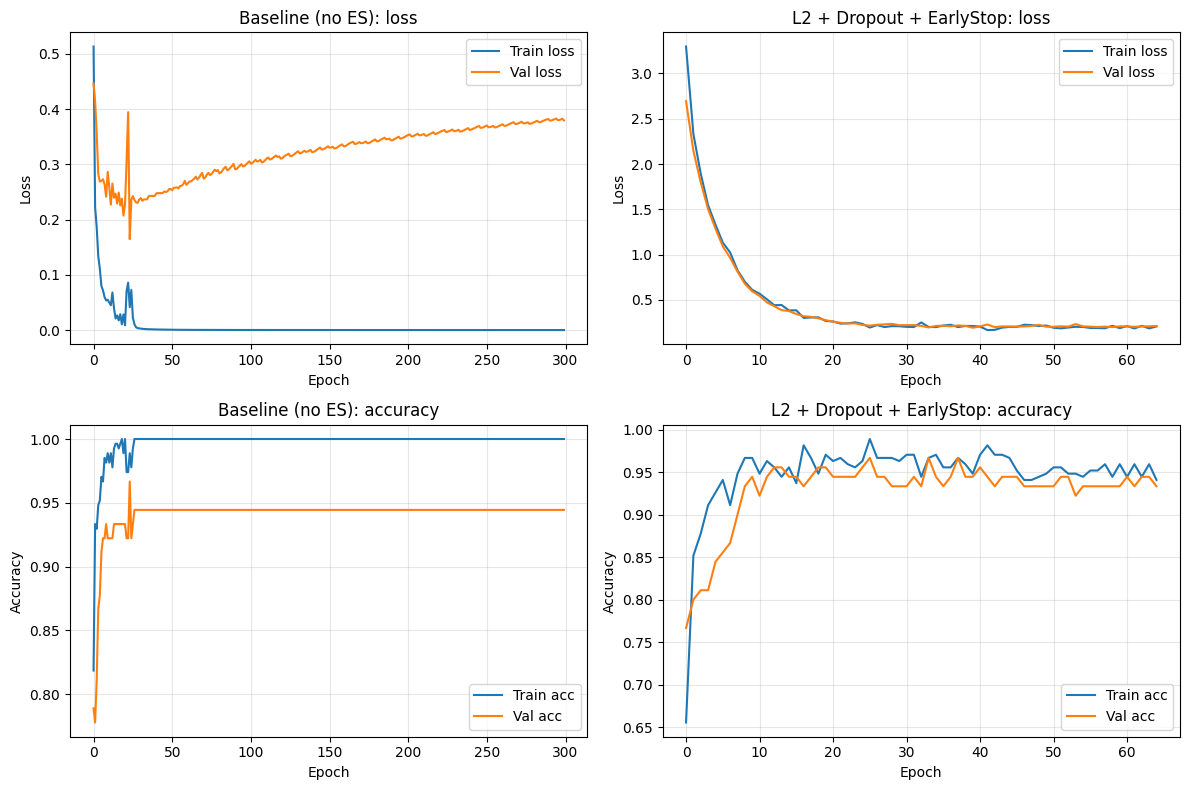


Baseline (no ES): min val loss 0.1646 at epoch 24; val loss at epoch 300 = 0.3794; train loss at epoch 300 = 0.0000
Baseline (no ES): final train acc 1.0000, final val acc 0.9444


In [8]:
# Learning curves: baseline (no ES) vs regularised
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for i, name in enumerate(["Baseline (no ES)", "L2 + Dropout + EarlyStop"]):
    tl, vl, ta, va, n = store[name]
    n = int(round(n)) if "ES" not in name and "Early" not in name else int(round(n))
    n = min(max(n, 1), MAXE)
    ax[0, i].plot(tl[:n], label="Train loss"); ax[0, i].plot(vl[:n], label="Val loss")
    ax[0, i].set(title=f"{name}: loss", xlabel="Epoch", ylabel="Loss")
    ax[1, i].plot(ta[:n], label="Train acc"); ax[1, i].plot(va[:n], label="Val acc")
    ax[1, i].set(title=f"{name}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    for r in (0, 1):
        ax[r, i].legend(); ax[r, i].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_learning_curves.png", dpi=150); plt.show()

# Gap analysis for the baseline (no ES) to justify the fit diagnosis
tl, vl, ta, va, _ = store["Baseline (no ES)"]
best_ep = int(np.argmin(vl)) + 1
print(f"\nBaseline (no ES): min val loss {vl.min():.4f} at epoch {best_ep}; "
      f"val loss at epoch {MAXE} = {vl[-1]:.4f}; train loss at epoch {MAXE} = {tl[-1]:.4f}")
print(f"Baseline (no ES): final train acc {ta[-1]:.4f}, final val acc {va[-1]:.4f}")

**Observation and conclusion (fit diagnosis):**
- **Baseline without early stopping → over-fitting.** Training loss falls to ≈ 0 and training accuracy reaches 100 %, while validation loss reaches its minimum (≈ 0.16) at about epoch 24 and then rises to ≈ 0.38 by epoch 300. The widening gap between training and validation loss is the signature of over-fitting (the network starts memorising the 90 training samples).
- **Early stopping** halts training near the validation-loss minimum (about 40 epochs on average) and restores the best weights, so validation loss stays low (≈ 0.16 instead of ≈ 0.38).
- **L2, L1 and dropout** (each with early stopping) give a lower validation loss than the baseline with early stopping (≈ 0.10–0.12 versus 0.157) and train longer before stopping because they slow memorisation. For the L2 + dropout model the reported loss (≈ 0.18) is higher only because Keras adds the weight-penalty term to the loss value; its training and validation curves are the closest together.
- **Selected model: L2 + dropout + early stopping** shows a *reasonable fit*: train and validation loss decrease together and stay close, and both accuracies plateau at about 93–97 %. It also obtained the best average test accuracy among the compared settings (≈ 95.6 %). Differences of one or two samples on a 30-sample set are small, so the ranking among the regularised variants should not be over-interpreted.

In [9]:
# ----------------------------------------------------------------------
# 6. Final model on the TEST set (selected configuration)
# ----------------------------------------------------------------------
print("\n=== FINAL MODEL: ReLU + He, 64-64, L2 + Dropout + EarlyStop, batch 8 ===")
h, t, model, _ = run(SEED, MAXE, 8, extra_callbacks=early_stop,
                     hidden=(64, 64), l2=1e-2, dropout=0.3)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(f"Stopped after {len(h['loss'])} epochs ({t:.2f} s)")
print(f"Test loss {test_loss:.4f} | Test accuracy {test_acc:.4f}")
print("Confusion matrix (rows = true, cols = predicted):")
print(confusion_matrix(y_test, pred))
print(f"\nAll figures saved in ./{OUT}/")


=== FINAL MODEL: ReLU + He, 64-64, L2 + Dropout + EarlyStop, batch 8 ===


Stopped after 96 epochs (27.33 s)
Test loss 0.1927 | Test accuracy 0.9667
Confusion matrix (rows = true, cols = predicted):
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]

All figures saved in ./task1_outputs/


The final model (one seed) classifies 29 of 30 test samples correctly (96.7 %); the only error is one Iris-versicolor sample predicted as Iris-virginica, which is the usual overlapping pair of classes in Iris.

# Task 2 — Adaline and Madaline Networks
**Input:** bipolar truth tables with inputs (−1,−1), (−1,+1), (+1,−1), (+1,+1). Targets: AND = (−1,−1,−1,+1); XOR = (−1,+1,+1,−1).

**Assumptions:** sign threshold maps a net input of exactly 0 to +1; Adaline is trained online (pattern-by-pattern) with learning rate 0.1.

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------- Bipolar data ----------------
X = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]], dtype=float)
T_and = np.array([-1, -1, -1, 1], dtype=float)
T_xor = np.array([-1, 1, 1, -1], dtype=float)

def sign(z):
    """Bipolar threshold. Tie (z == 0) -> +1 (documented assumption)."""
    return np.where(z >= 0, 1.0, -1.0)

In [11]:
# ---------------- Part A: Adaline ----------------
class Adaline:
    """Adaline: net = w.x + b (linear), prediction = sign(net).
    Training loss  : L = 1/2 * mean over patterns of (t - net)^2   (MSE with 1/2 factor)
    Delta/LMS rule : w <- w + lr*(t - net)*x ,  b <- b + lr*(t - net)
    (the error is taken on the LINEAR net input, not on the thresholded output)."""
    def __init__(self, n_inputs, lr=0.1, seed=0):
        rng = np.random.default_rng(seed)
        self.w = rng.uniform(-0.1, 0.1, n_inputs)
        self.b = 0.0
        self.lr = lr

    def net(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return sign(self.net(X))

    def fit(self, X, t, epochs=30):
        mse_hist, err_hist = [], []
        for _ in range(epochs):
            for xi, ti in zip(X, t):          # online (pattern-by-pattern) LMS
                e = ti - (xi @ self.w + self.b)
                self.w += self.lr * e * xi
                self.b += self.lr * e
            mse_hist.append(np.mean((t - self.net(X)) ** 2))
            err_hist.append(int(np.sum(self.predict(X) != t)))
        return mse_hist, err_hist

=== PART A: ADALINE on bipolar AND ===
Learned weights : [0.5294 0.5588]
Learned bias    : -0.5
 x1  x2 | target |      net | pred
 -1  -1 |     -1 |  -1.5882 |   -1
 -1   1 |     -1 |  -0.4706 |   -1
  1  -1 |     -1 |  -0.5294 |   -1
  1   1 |      1 |   0.5882 |    1
Classification errors reach 0 at epoch 1
Final MSE = 0.2543  (theoretical LMS minimum = 0.25)


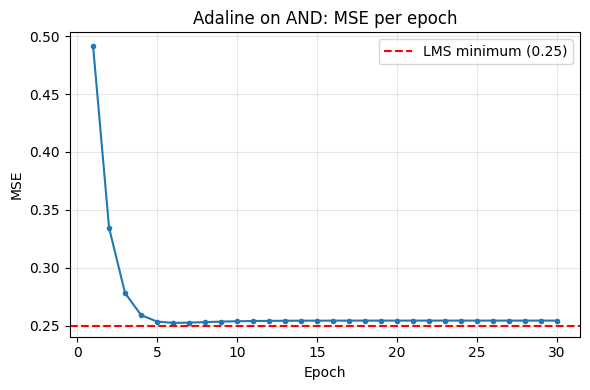

In [12]:
print("=== PART A: ADALINE on bipolar AND ===")
ada = Adaline(2, lr=0.1, seed=1)
mse_and, err_and = ada.fit(X, T_and, epochs=30)
print("Learned weights :", np.round(ada.w, 4))
print("Learned bias    :", round(ada.b, 4))
print(f"{'x1':>3} {'x2':>3} | {'target':>6} | {'net':>8} | {'pred':>4}")
for xi, ti, ni, pi in zip(X, T_and, ada.net(X), ada.predict(X)):
    print(f"{int(xi[0]):>3} {int(xi[1]):>3} | {int(ti):>6} | {ni:8.4f} | {int(pi):>4}")
first_zero_err = next(i + 1 for i, e in enumerate(err_and) if e == 0)
print(f"Classification errors reach 0 at epoch {first_zero_err}")
print(f"Final MSE = {mse_and[-1]:.4f}  (theoretical LMS minimum = 0.25)")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 31), mse_and, marker="o", ms=3)
plt.axhline(0.25, color="r", ls="--", label="LMS minimum (0.25)")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Adaline on AND: MSE per epoch")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

### Part A — Adaline: loss function and convergence
- **Net input:** y_in = w·x + b (linear); **prediction:** sign(y_in).
- **Loss function:** mean squared error on the *linear* net input, L = ½·(1/P)·Σ(t − y_in)². (The printed/plotted MSE omits the factor ½.)
- **Delta / LMS rule:** w ← w + η(t − y_in)x, b ← b + η(t − y_in), with η = 0.1.
- **Result:** the learned parameters are close to the least-squares solution w = (0.5, 0.5), b = −0.5, and all four AND patterns are classified correctly (the classification error is already 0 after the first epoch).
- **Convergence:** the MSE decreases rapidly and settles at about 0.25, which is the minimum possible. It cannot reach 0 because a *linear* output cannot equal ±1 exactly on all four points (the best-fit net values are −1.5, −0.5, −0.5, +0.5). The weights therefore converge to the LMS optimum (with a tiny oscillation from the constant learning rate), while the *classification* is perfect.

In [13]:
# Single Adaline on XOR (to show it cannot solve it)
print("\n=== Single Adaline on bipolar XOR ===")
ada_x = Adaline(2, lr=0.1, seed=1)
mse_x, err_x = ada_x.fit(X, T_xor, epochs=100)
print("Weights:", np.round(ada_x.w, 4), "| bias:", round(ada_x.b, 4))
print("Predictions:", ada_x.predict(X).astype(int), "| targets:", T_xor.astype(int))
print(f"Final MSE = {mse_x[-1]:.4f} | misclassified patterns = {err_x[-1]} of 4")


=== Single Adaline on bipolar XOR ===
Weights: [-0.0588 -0.1176] | bias: -0.0
Predictions: [ 1 -1  1 -1] | targets: [-1  1  1 -1]
Final MSE = 1.0173 | misclassified patterns = 2 of 4


**Single Adaline on XOR:** the MSE stays at about 1.0 (the weights stay near 0, so the output is near 0 for every pattern) and 2 of 4 patterns are misclassified. Training longer cannot fix this because no linear function separates XOR.

In [14]:
# ---------------- Part B: Madaline (MRII) ----------------
class Madaline:
    """Madaline: 2 -> H hidden Adaline units (bipolar) -> 1 FIXED output unit.
    Hidden unit j : z_j = sign(v_j . x + c_j)
    Output unit   : y = sign(sum_j z_j + (H - 1))   -> logical OR of the hidden units
                    (fixed weights = 1, bias = H-1, NOT trained, as in Madaline Rule I/II)
    Learning (MRII, Widrow):
      for each pattern whose output y != t:
        1. rank hidden units by |net_j| (closest to the threshold first);
        2. TRIAL-FLIP the closest unit: set its desired output = -z_j and apply an
           LMS step toward that desired value  (v <- v + lr*(d - net)*x);
        3. keep the change only if the network output becomes correct (or error count
           over all patterns decreases); otherwise undo it and try the next unit;
        4. if no single flip helps, try flipping the two closest units together.
    """
    def __init__(self, n_inputs=2, n_hidden=2, lr=0.5, seed=0):
        rng = np.random.default_rng(seed)
        self.V = rng.uniform(-0.5, 0.5, (n_hidden, n_inputs))
        self.c = rng.uniform(-0.5, 0.5, n_hidden)
        self.H = n_hidden
        self.lr = lr

    def hidden_net(self, X):
        return X @ self.V.T + self.c

    def hidden(self, X):
        return sign(self.hidden_net(X))

    def predict(self, X):
        return sign(self.hidden(X).sum(axis=1) + (self.H - 1))

    def n_errors(self, X, t):
        return int(np.sum(self.predict(X) != t))

    def fit(self, X, t, epochs=200):
        err_hist = []
        for ep in range(epochs):
            for xi, ti in zip(X, t):
                if self.predict(xi[None])[0] == ti:
                    continue
                nets = self.hidden_net(xi[None])[0]
                order = np.argsort(np.abs(nets))
                base_err = self.n_errors(X, t)
                trials = [[j] for j in order] + [list(order[:2])]
                for units in trials:
                    V0, c0 = self.V.copy(), self.c.copy()
                    for j in units:
                        d = -np.sign(nets[j]) if nets[j] != 0 else -1.0
                        # LMS push beyond the threshold toward the flipped value
                        e = d - nets[j]
                        self.V[j] += self.lr * e * xi
                        self.c[j] += self.lr * e
                    if self.predict(xi[None])[0] == ti and self.n_errors(X, t) <= base_err:
                        break                      # accept
                    self.V, self.c = V0, c0        # reject -> undo
            err_hist.append(self.n_errors(X, t))
            if err_hist[-1] == 0:
                break
        return err_hist


=== PART B: MADALINE (MRII) on bipolar XOR ===


Converged with random-init seed 4 after 2 epoch(s)
Hidden weights V (rows = hidden units):
 [[-0.949  1.607]
 [ 0.476 -0.419]]
Hidden biases c: [-0.724 -0.124]
 x1  x2 |  h1  h2 | target | pred
 -1  -1 |  -1  -1 |     -1 |   -1
 -1   1 |   1  -1 |      1 |    1
  1  -1 |  -1   1 |      1 |    1
  1   1 |  -1  -1 |     -1 |   -1


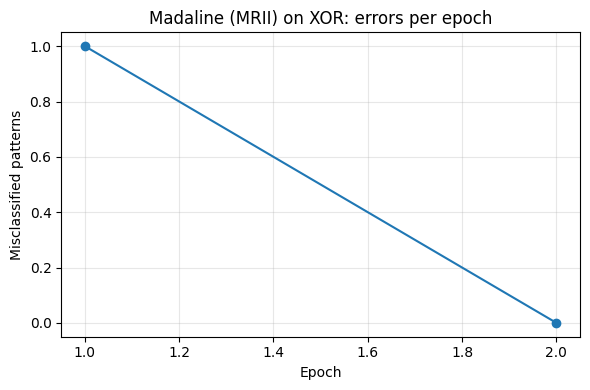

In [15]:
print("\n=== PART B: MADALINE (MRII) on bipolar XOR ===")
for seed in range(50):
    mad = Madaline(2, 2, lr=0.5, seed=seed)
    err_hist = mad.fit(X, T_xor, epochs=200)
    if err_hist[-1] == 0:
        break
print(f"Converged with random-init seed {seed} after {len(err_hist)} epoch(s)")
print("Hidden weights V (rows = hidden units):\n", np.round(mad.V, 3))
print("Hidden biases c:", np.round(mad.c, 3))
print(f"{'x1':>3} {'x2':>3} | {'h1':>3} {'h2':>3} | {'target':>6} | {'pred':>4}")
H = mad.hidden(X).astype(int)
for xi, hi, ti, pi in zip(X, H, T_xor, mad.predict(X)):
    print(f"{int(xi[0]):>3} {int(xi[1]):>3} | {hi[0]:>3} {hi[1]:>3} | {int(ti):>6} | {int(pi):>4}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(err_hist) + 1), err_hist, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Misclassified patterns")
plt.title("Madaline (MRII) on XOR: errors per epoch")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Part B — Madaline architecture and learning rule
- **Architecture:** 2 inputs → **2 hidden Adaline units** (bipolar output z_j = sign(v_j·x + c_j)) → **1 fixed output unit** y = sign(z₁ + z₂ + 1), i.e. a logical OR of the hidden units (fixed weights 1, 1 and bias 1; not trained).
- **Learning rule (Madaline Rule II, trial-flip):** for every misclassified pattern, the hidden unit whose net input is closest to 0 is flipped by an LMS step toward the opposite sign; the change is kept only if the network output becomes correct without increasing the total number of errors, otherwise it is undone and the next unit is tried (finally the two closest units together).
- **Result:** the network learns XOR in 2 epochs (error count drops to 0). Hidden unit 1 fires (+1) only for (−,+) and hidden unit 2 only for (+,−), so the OR output gives (−1, +1, +1, −1).
- **Assumption/limitation:** Rule II is a heuristic and can stall from some initial weights, so the code tries up to 50 random initialisations until one converges (here the 5th, seed 4).

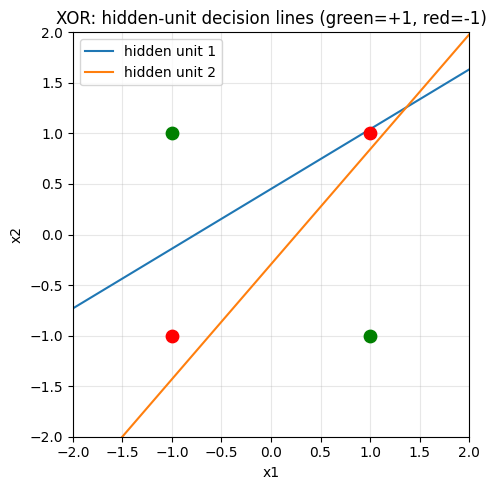

In [16]:
# decision boundaries of the two hidden units
plt.figure(figsize=(5, 5))
xs = np.linspace(-2, 2, 100)
for j in range(2):
    v, c = mad.V[j], mad.c[j]
    if abs(v[1]) > 1e-9:
        plt.plot(xs, -(v[0] * xs + c) / v[1], label=f"hidden unit {j+1}")
for xi, ti in zip(X, T_xor):
    plt.scatter(*xi, c="g" if ti == 1 else "r", s=80, zorder=3)
plt.xlim(-2, 2); plt.ylim(-2, 2); plt.legend(); plt.grid(alpha=0.3)
plt.title("XOR: hidden-unit decision lines (green=+1, red=-1)")
plt.xlabel("x1"); plt.ylabel("x2"); plt.tight_layout(); plt.show()

### Why a single Adaline cannot solve XOR, but a network with hidden units can
A single Adaline's decision boundary is one straight line w₁x₁ + w₂x₂ + b = 0. XOR would need (−1,−1) and (+1,+1) on the negative side, and (−1,+1) and (+1,−1) on the positive side:
- (−1,−1): −w₁ − w₂ + b < 0 and (+1,+1): w₁ + w₂ + b < 0 → adding gives **b < 0**;
- (−1,+1): −w₁ + w₂ + b > 0 and (+1,−1): w₁ − w₂ + b > 0 → adding gives **b > 0**.

These conditions contradict each other, so XOR is not linearly separable. In the Madaline each hidden unit draws its own line (see the plot above); one line isolates (−,+) and the other isolates (+,−). The output unit combines the two half-planes with OR, giving a **non-linear (piece-wise linear) decision region** that separates XOR correctly.

# Task 3 — Pattern Association and Associative Memory
**Input:** bipolar patterns written as strings of `+` (+1) and `-` (−1).

- **Heteroassociative memory:** maps an input pattern x to a *different* output pattern y (x ≠ y, here 6 bits → 4 bits). **Rule:** Hebbian outer-product W = Σ yₚᵀxₚ; recall y = sign(Wx).
- **Autoassociative memory:** maps a pattern to itself, so a noisy/partial pattern can be completed (here 12 bits). **Rule:** W = Σ pₚᵀpₚ; recall out = sign(Wq).
- Ties (net input 0) are mapped to +1.

In [17]:
import numpy as np
import pandas as pd

def sign(z):
    """Bipolar threshold; tie (0) -> +1 (documented assumption)."""
    return np.where(z >= 0, 1, -1)

def s(txt):
    """'+--+' -> np.array([1,-1,-1,1])"""
    return np.array([1 if ch == "+" else -1 for ch in txt])

def show(v):
    return "".join("+" if a > 0 else "-" for a in v)

In [18]:
# ======================= PART A: HETEROASSOCIATIVE MEMORY =======================
# Rule (Hebbian outer-product, "correlation matrix memory"):
#     W = sum_p  y_p^T x_p        (shape: n_out x n_in)
#     recall: y = sign(W x)
# Input pairs chosen (nearly) orthogonal so cross-talk is small.
X_het = [s("+-+-+-"), s("++--++"), s("+--++-")]       # inputs  (6 bits)
Y_het = [s("+--+"),   s("-++-"),   s("++--")]         # outputs (4 bits)

W_het = sum(np.outer(y, x) for x, y in zip(X_het, Y_het))
print("=== HETEROASSOCIATIVE MEMORY ===")
print("Stored pairs (x -> y):")
for x, y in zip(X_het, Y_het):
    print(f"  {show(x)} -> {show(y)}")
print("Weight matrix W (4 x 6):\n", W_het)
print("Input-pattern dot products (cross-talk check):",
      [int(X_het[i] @ X_het[j]) for i in range(3) for j in range(i + 1, 3)])

=== HETEROASSOCIATIVE MEMORY ===
Stored pairs (x -> y):
  +-+-+- -> +--+
  ++--++ -> -++-
  +--++- -> ++--
Weight matrix W (4 x 6):
 [[ 1 -3  1  1  1 -3]
 [ 1  1 -3  1  1  1]
 [-1  3 -1 -1 -1  3]
 [-1 -1  3 -1 -1 -1]]
Input-pattern dot products (cross-talk check): [0, 2, 0]


In [19]:
rows = []
for x, y in zip(X_het, Y_het):
    out = sign(W_het @ x)
    rows.append(["Stored pair", show(x), "none (clean)", show(out), show(y), bool(np.array_equal(out, y))])
# noisy queries: flip k bits of each stored input
for k in (1, 2):
    for x, y in zip(X_het, Y_het):
        q = x.copy(); q[:k] *= -1
        out = sign(W_het @ q)
        rows.append(["Stored pair", show(x), f"{k} bit(s) flipped -> {show(q)}",
                     show(out), show(y), bool(np.array_equal(out, y))])
df_het = pd.DataFrame(rows, columns=["Type", "Stored input", "Query / noise applied",
                                     "Recalled output", "Expected output", "Exact match"])
print("\nHeteroassociative recall table:")
print(df_het.to_string(index=False))


Heteroassociative recall table:
       Type Stored input      Query / noise applied Recalled output Expected output  Exact match
Stored pair       +-+-+-               none (clean)            +--+            +--+         True
Stored pair       ++--++               none (clean)            -++-            -++-         True
Stored pair       +--++-               none (clean)            ++--            ++--         True
Stored pair       +-+-+- 1 bit(s) flipped -> --+-+-            +--+            +--+         True
Stored pair       ++--++ 1 bit(s) flipped -> -+--++            -++-            -++-         True
Stored pair       +--++- 1 bit(s) flipped -> ---++-            ++--            ++--         True
Stored pair       +-+-+- 2 bit(s) flipped -> -++-+-            +-++            +--+        False
Stored pair       ++--++ 2 bit(s) flipped -> ----++            -++-            -++-         True
Stored pair       +--++- 2 bit(s) flipped -> -+-++-            +++-            ++--        Fal

**Heteroassociative result:** all 3 stored inputs are recalled exactly, and so are all 3 inputs with 1 flipped bit. With 2 flipped bits, 1 of 3 pairs (pair 2) is recalled correctly while pairs 1 and 3 fail (2 failures). **Limitation:** the Hebbian rule is exact only when the stored inputs are orthogonal; here inputs 1 and 3 have a dot product of 2, so their cross-talk reduces the noise margin, and a 2-bit error in a 6-bit input is large (one third of the input).

In [20]:
# ======================= PART B: AUTOASSOCIATIVE MEMORY =========================
# Rule: W = sum_p p^T p  (outer product of each pattern with itself), diagonal kept.
#       recall (one-shot): out = sign(W q)
P_auto = [s("+-+-+-+-+-+-"), s("++--++--++--"), s("+++---+++---")]  # 12 bits
W_auto = sum(np.outer(p, p) for p in P_auto)
print("\n=== AUTOASSOCIATIVE MEMORY ===")
for i, p in enumerate(P_auto, 1):
    print(f"  P{i} = {show(p)}")
print("Pairwise dot products:", [int(P_auto[i] @ P_auto[j]) for i in range(3) for j in range(i + 1, 3)])


=== AUTOASSOCIATIVE MEMORY ===
  P1 = +-+-+-+-+-+-
  P2 = ++--++--++--
  P3 = +++---+++---
Pairwise dot products: [0, 4, 0]


In [21]:
rows = []
for i, p in enumerate(P_auto, 1):
    for k in (0, 1, 2, 3, 4, 5):
        q = p.copy()
        idx = np.arange(k) * 2                  # flip bits 0,2,4,... (deterministic)
        q[idx] *= -1
        out = sign(W_auto @ q)
        rows.append([f"P{i}: {show(p)}", "clean" if k == 0 else f"{k} bit(s) flipped -> {show(q)}",
                     show(out), bool(np.array_equal(out, p))])
df_auto = pd.DataFrame(rows, columns=["Stored pattern", "Query / noise applied",
                                      "Recalled output", "Exact match"])
print("\nAutoassociative recall table:")
print(df_auto.to_string(index=False))

n_ok = int(df_auto["Exact match"].sum())
print(f"\nAutoassociative exact matches: {n_ok}/{len(df_auto)}")
print("Failures:")
print(df_auto[~df_auto["Exact match"]].to_string(index=False))


Autoassociative recall table:
  Stored pattern            Query / noise applied Recalled output  Exact match
P1: +-+-+-+-+-+-                            clean    +-+-+-+-+-+-         True
P1: +-+-+-+-+-+- 1 bit(s) flipped -> --+-+-+-+-+-    +-+-+-+-+-+-         True
P1: +-+-+-+-+-+- 2 bit(s) flipped -> ----+-+-+-+-    +-+-+-+-+-+-         True
P1: +-+-+-+-+-+- 3 bit(s) flipped -> ------+-+-+-    +-+-+-+-+-+-         True
P1: +-+-+-+-+-+- 4 bit(s) flipped -> --------+-+-    +-+-+-+-+-+-         True
P1: +-+-+-+-+-+- 5 bit(s) flipped -> ----------+-    --+++-+---++        False
P2: ++--++--++--                            clean    ++--++--++--         True
P2: ++--++--++-- 1 bit(s) flipped -> -+--++--++--    ++--++--++--         True
P2: ++--++--++-- 2 bit(s) flipped -> -++-++--++--    ++--++--++--         True
P2: ++--++--++-- 3 bit(s) flipped -> -++--+--++--    ++--++--++--         True
P2: ++--++--++-- 4 bit(s) flipped -> -++--++-++--    +++-++++++--        False
P2: ++--++--++-- 5 bi

**Autoassociative result:** all three clean patterns and all queries with 1–3 flipped bits are recalled exactly (13 of 18 queries in total). The 5 failures are queries with 4–5 flipped bits (P1 fails only at 5 flips; P2 and P3 fail at 4 and 5 flips): the recalled output is then a spurious pattern that was never stored.

**Failure case / limitation:** recall is a single matrix–sign step, so there is no iteration to clean up the output, and the patterns are not perfectly orthogonal (P1 and P3 have a dot product of 4), so cross-talk adds noise to each net input. When the corruption approaches or exceeds a third of the 12 bits, the noise terms outweigh the stored pattern's contribution and the result is wrong. The memory capacity is also small relative to the number of neurons.

# Task 4 — Hopfield Network: Storage, Recall, Energy, and Analysis
**Input:** three 4×4 bipolar patterns (N = 16 neurons; `#` = +1, `.` = −1): an X shape, horizontal stripes and a checkerboard. They are mutually orthogonal (all dot products are 0).

- **Storage (Hebbian):** W = Σ pₚpₚᵀ with the diagonal set to zero (an integer matrix is shown; dividing by N would not change any sign update).
- **Recall:** asynchronous — one neuron at a time, in a random order each sweep, s_i ← sign(Σⱼ w_ij s_j), until a full sweep changes nothing (maximum 20 sweeps).
- **Tie rule:** if the net input is exactly 0, the neuron **keeps its current state**.
- **Energy:** E = −½ Σᵢ Σⱼ w_ij s_i s_j.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rng = np.random.default_rng(7)

def s(txt):
    return np.array([1 if ch == "#" else -1 for ch in txt.replace("\n", "").replace(" ", "")])

def grid(v):
    return "\n".join("".join("#" if a > 0 else "." for a in v[r*4:(r+1)*4]) for r in range(4))

# Three 4x4 bipolar patterns (N = 16 neurons)
P = [
    s("#..#  .##.  .##.  #..#"),   # P1: X
    s("####  ....  ####  ...."),   # P2: horizontal stripes
    s("#.#.  .#.#  #.#.  .#.#"),   # P3: checkerboard
]
N = len(P[0])
names = ["P1 (X)", "P2 (stripes)", "P3 (checker)"]
print("Stored patterns ('#'=+1, '.'=-1):")
for n, p in zip(names, P):
    print(n); print(grid(p)); print()
print("Pairwise dot products (cross-talk):", [int(P[i] @ P[j]) for i in range(3) for j in range(i + 1, 3)])

Stored patterns ('#'=+1, '.'=-1):
P1 (X)
#..#
.##.
.##.
#..#

P2 (stripes)
####
....
####
....

P3 (checker)
#.#.
.#.#
#.#.
.#.#

Pairwise dot products (cross-talk): [0, 0, 0]


In [23]:
# ---------------- Hebbian storage ----------------
# W = sum_p p p^T  with zero diagonal (integer matrix shown; scaling by 1/N does not change the sign updates)
W = sum(np.outer(p, p) for p in P).astype(float)
np.fill_diagonal(W, 0)
print("\nHopfield weight matrix W (16 x 16, diagonal = 0):")
print(W.astype(int))
print("Symmetric:", np.allclose(W, W.T), "| diagonal all zero:", np.all(np.diag(W) == 0))

def energy(state):
    """E = -1/2 sum_i sum_j w_ij s_i s_j"""
    return -0.5 * state @ W @ state


Hopfield weight matrix W (16 x 16, diagonal = 0):
[[ 0 -1  1  1 -3  1 -1 -1  1  1  3 -1 -1 -1 -3  1]
 [-1  0  1  1  1 -3 -1 -1  1  1 -1  3 -1 -1  1 -3]
 [ 1  1  0 -1 -1 -1 -3  1  3 -1  1  1 -3  1 -1 -1]
 [ 1  1 -1  0 -1 -1  1 -3 -1  3  1  1  1 -3 -1 -1]
 [-3  1 -1 -1  0 -1  1  1 -1 -1 -3  1  1  1  3 -1]
 [ 1 -3 -1 -1 -1  0  1  1 -1 -1  1 -3  1  1 -1  3]
 [-1 -1 -3  1  1  1  0 -1 -3  1 -1 -1  3 -1  1  1]
 [-1 -1  1 -3  1  1 -1  0  1 -3 -1 -1 -1  3  1  1]
 [ 1  1  3 -1 -1 -1 -3  1  0 -1  1  1 -3  1 -1 -1]
 [ 1  1 -1  3 -1 -1  1 -3 -1  0  1  1  1 -3 -1 -1]
 [ 3 -1  1  1 -3  1 -1 -1  1  1  0 -1 -1 -1 -3  1]
 [-1  3  1  1  1 -3 -1 -1  1  1 -1  0 -1 -1  1 -3]
 [-1 -1 -3  1  1  1  3 -1 -3  1 -1 -1  0 -1  1  1]
 [-1 -1  1 -3  1  1 -1  3  1 -3 -1 -1 -1  0  1  1]
 [-3  1 -1 -1  3 -1  1  1 -1 -1 -3  1  1  1  0 -1]
 [ 1 -3 -1 -1 -1  3  1  1 -1 -1  1 -3  1  1 -1  0]]
Symmetric: True | diagonal all zero: True


In [24]:
# ---------------- Asynchronous recall ----------------
def recall(state, max_sweeps=20, rng=rng, track=False):
    """Asynchronous update: one neuron at a time in a random order each sweep.
       s_i <- sign(sum_j w_ij s_j).  TIE RULE: if the net input is exactly 0 the neuron KEEPS its current state.
       Stops when a full sweep changes nothing (stable) or max_sweeps*N updates are done."""
    s_ = state.copy()
    log = []                                    # (update#, neuron, net, old, new, energy)
    updates = 0
    for sweep in range(max_sweeps):
        changed = False
        for i in rng.permutation(N):
            h = W[i] @ s_
            new = s_[i] if h == 0 else (1 if h > 0 else -1)
            updates += 1
            changed_now = bool(new != s_[i])
            if changed_now:
                changed = True
            s_[i] = new
            if track:
                log.append((updates, i, h, new, energy(s_), changed_now))
        if not changed:
            break
    return s_, updates, log

def corrupt(p, k, rng):
    q = p.copy()
    idx = rng.choice(N, size=k, replace=False)
    q[idx] *= -1
    return q

In [25]:
# ---------------- Test 1: every stored pattern is a stable state ----------------
print("\n=== Stability of stored patterns (clean input) ===")
for n, p in zip(names, P):
    out, _, _ = recall(p)
    print(f"{n}: stays stable = {np.array_equal(out, p)}")


=== Stability of stored patterns (clean input) ===
P1 (X): stays stable = True
P2 (stripes): stays stable = True
P3 (checker): stays stable = True



=== Recall success rate (200 random corruptions per row) ===
     Pattern  Bits flipped  Exact recalls  Trials  Success rate (%)
      P1 (X)             1            200     200             100.0
      P1 (X)             2            200     200             100.0
      P1 (X)             3            178     200              89.0
      P1 (X)             4            160     200              80.0
      P1 (X)             5             97     200              48.5
      P1 (X)             6             63     200              31.5
P2 (stripes)             1            200     200             100.0
P2 (stripes)             2            200     200             100.0
P2 (stripes)             3            170     200              85.0
P2 (stripes)             4            170     200              85.0
P2 (stripes)             5            101     200              50.5
P2 (stripes)             6             65     200              32.5
P3 (checker)             1            200     200     

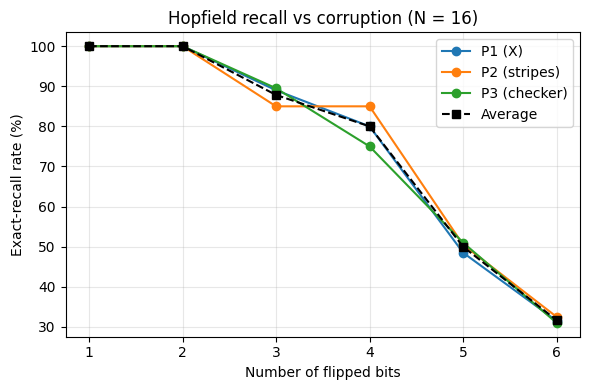

In [26]:
# ---------------- Test 2: recall from corrupted versions ----------------
TRIALS = 200
flips = [1, 2, 3, 4, 5, 6]
rows = []
for n, p in zip(names, P):
    for k in flips:
        ok = 0
        for _ in range(TRIALS):
            out, _, _ = recall(corrupt(p, k, rng))
            ok += int(np.array_equal(out, p))
        rows.append([n, k, ok, TRIALS, 100 * ok / TRIALS])
df = pd.DataFrame(rows, columns=["Pattern", "Bits flipped", "Exact recalls", "Trials", "Success rate (%)"])
print(f"\n=== Recall success rate ({TRIALS} random corruptions per row) ===")
print(df.to_string(index=False))
piv = df.pivot(index="Bits flipped", columns="Pattern", values="Success rate (%)")[names]
piv["Average"] = piv.mean(axis=1)
print("\nSummary (success rate %):")
print(piv.round(1).to_string())

plt.figure(figsize=(6, 4))
for n in names:
    plt.plot(flips, piv[n], marker="o", label=n)
plt.plot(flips, piv["Average"], "k--", marker="s", label="Average")
plt.xlabel("Number of flipped bits"); plt.ylabel("Exact-recall rate (%)")
plt.title("Hopfield recall vs corruption (N = 16)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Recall analysis
- The weight matrix is symmetric with a zero diagonal, and all three stored patterns are **stable states** (clean input stays unchanged).
- **Recall success rate** (exact match, 200 random corruptions per case): 100 % for 1–2 flipped bits, about 88 % for 3, 80 % for 4, 50 % for 5 and 32 % for 6 flipped bits (average over the three patterns).
- Success drops with more flipped bits because a heavily corrupted input can lie closer to another attractor: the *negative* of a stored pattern (−P) is also a stable state of a Hebbian network, and mixed (spurious) states can exist. Storing 3 patterns in 16 neurons (load 0.19) is also above the theoretical capacity of about 0.138·N ≈ 2 patterns for reliable recall, so the basins of attraction are small.


=== Energy tracking example: P1 (X) with 4 flipped bits ===
Corrupted input:
###.
.##.
.#..
#..#
Energy of stored P1 = -104.0 | Energy of corrupted input = -8.0

Total asynchronous updates until stable: 32 (the table lists only updates that flipped a neuron)
Update | neuron | net input | new state | energy
     5 |      3 |      11.0 |         1 |   -30.0
     8 |     10 |      13.0 |         1 |   -56.0
    10 |      1 |     -11.0 |        -1 |   -78.0
    11 |      2 |     -13.0 |        -1 |  -104.0

Recalled pattern:
#..#
.##.
.##.
#..#
Matches stored P1: True
Energy never increased: True


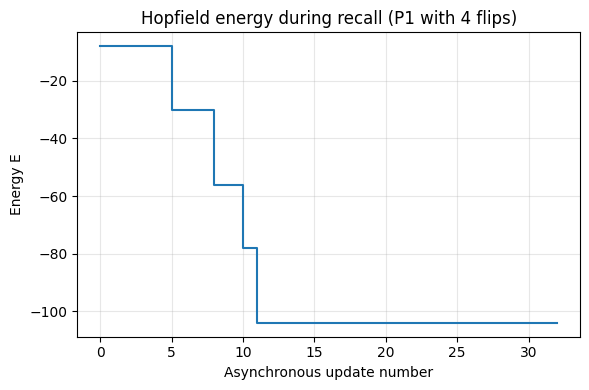

In [27]:
# ---------------- Energy tracking: step-by-step example ----------------
rng_demo = np.random.default_rng(3)
query = corrupt(P[0], 4, rng_demo)
print("\n=== Energy tracking example: P1 (X) with 4 flipped bits ===")
print("Corrupted input:"); print(grid(query))
print(f"Energy of stored P1 = {energy(P[0]):.1f} | Energy of corrupted input = {energy(query):.1f}")
out, n_updates, log = recall(query, rng=rng_demo, track=True)
print(f"\nTotal asynchronous updates until stable: {n_updates} (the table lists only updates that flipped a neuron)")
print("Update | neuron | net input | new state | energy")
E_trace = [energy(query)]
for (u, i, h, new, e, flipped) in log:
    E_trace.append(e)
    if flipped:
        print(f"{u:>6} | {i:>6} | {h:>9.1f} | {new:>9} | {e:>7.1f}")
print("\nRecalled pattern:"); print(grid(out))
print("Matches stored P1:", np.array_equal(out, P[0]))
print("Energy never increased:", bool(np.all(np.diff(E_trace) <= 1e-9)))

plt.figure(figsize=(6, 4))
plt.step(range(len(E_trace)), E_trace, where="post")
plt.xlabel("Asynchronous update number"); plt.ylabel("Energy E")
plt.title("Hopfield energy during recall (P1 with 4 flips)")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Energy intuition
In the example, the corrupted input has energy −8 and the stored pattern P1 has the much lower energy −104. Every asynchronous update that flips a neuron lowers the energy (−8 → −30 → −56 → −78 → −104) and the network stops when it reaches the stored pattern, a local minimum. Because W is symmetric with a zero diagonal and only one neuron is updated at a time, an update can never increase E, so the dynamics must settle in a stable state. The stored patterns are the minima of this "energy landscape", and recall is a *descent* from the corrupted input into the nearest minimum. Updates that do not flip a neuron leave E unchanged (flat steps in the plot).